In [1]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [3]:
dataset = pd.read_csv('/content/sample_data/Social_Network_Ads.csv')

In [8]:
X=dataset.iloc[:,[2,3]].values
y=dataset.iloc[:,4].values
print(X)
print(y)

[[    19  19000]
 [    35  20000]
 [    26  43000]
 [    27  57000]
 [    19  76000]
 [    27  58000]
 [    27  84000]
 [    32 150000]
 [    25  33000]
 [    35  65000]
 [    26  80000]
 [    26  52000]
 [    20  86000]
 [    32  18000]
 [    18  82000]
 [    29  80000]
 [    47  25000]
 [    45  26000]
 [    46  28000]
 [    48  29000]
 [    45  22000]
 [    47  49000]
 [    48  41000]
 [    45  22000]
 [    46  23000]
 [    47  20000]
 [    49  28000]
 [    47  30000]
 [    29  43000]
 [    31  18000]
 [    31  74000]
 [    27 137000]
 [    21  16000]
 [    28  44000]
 [    27  90000]
 [    35  27000]
 [    33  28000]
 [    30  49000]
 [    26  72000]
 [    27  31000]
 [    27  17000]
 [    33  51000]
 [    35 108000]
 [    30  15000]
 [    28  84000]
 [    23  20000]
 [    25  79000]
 [    27  54000]
 [    30 135000]
 [    31  89000]
 [    24  32000]
 [    18  44000]
 [    29  83000]
 [    35  23000]
 [    27  58000]
 [    24  55000]
 [    23  48000]
 [    28  79000]
 [    22  1800

In [10]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 0)

In [11]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report

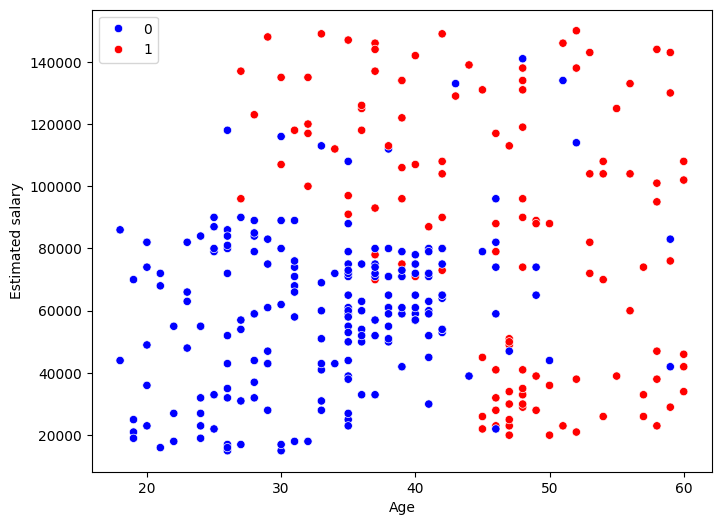

In [12]:
# --- 1. Initial Visualization (Unscaled Data) ---
plt.figure(figsize=(8, 6))
sns.scatterplot(x=X_train[:, 0], y=X_train[:, 1], hue=y_train, palette={0: 'blue', 1: 'red'}, marker='o')
plt.xlabel("Age")
plt.ylabel("Estimated salary")
plt.show()

In [13]:
# --- 2. Feature Scaling ---
sc = StandardScaler()
X_train_scaled = sc.fit_transform(X_train)
X_test_scaled = sc.transform(X_test)

In [14]:
print(X_train_scaled)
print(X_test_scaled)

[[ 1.92295008e+00  2.14601566e+00]
 [ 2.02016082e+00  3.78719297e-01]
 [-1.38221530e+00 -4.32498705e-01]
 [-1.18779381e+00 -1.01194013e+00]
 [ 1.92295008e+00 -9.25023920e-01]
 [ 3.67578135e-01  2.91803083e-01]
 [ 1.73156642e-01  1.46942725e-01]
 [ 2.02016082e+00  1.74040666e+00]
 [ 7.56421121e-01 -8.38107706e-01]
 [ 2.70367388e-01 -2.87638347e-01]
 [ 3.67578135e-01 -1.71750061e-01]
 [-1.18475597e-01  2.20395980e+00]
 [-1.47942605e+00 -6.35303205e-01]
 [-1.28500455e+00 -1.06988428e+00]
 [-1.38221530e+00  4.07691369e-01]
 [-1.09058306e+00  7.55356227e-01]
 [-1.47942605e+00 -2.00722133e-01]
 [ 9.50842613e-01 -1.06988428e+00]
 [ 9.50842613e-01  5.81523798e-01]
 [ 3.67578135e-01  9.87132798e-01]
 [ 5.61999628e-01 -8.96051849e-01]
 [-6.04529329e-01  1.45068594e+00]
 [-2.12648508e-02 -5.77359062e-01]
 [-6.04529329e-01  1.88526701e+00]
 [ 1.33968560e+00 -1.41754914e+00]
 [ 1.43689635e+00  9.87132798e-01]
 [ 7.59458956e-02 -8.09135634e-01]
 [-2.12648508e-02 -2.58666276e-01]
 [-2.15686344e-01 -5

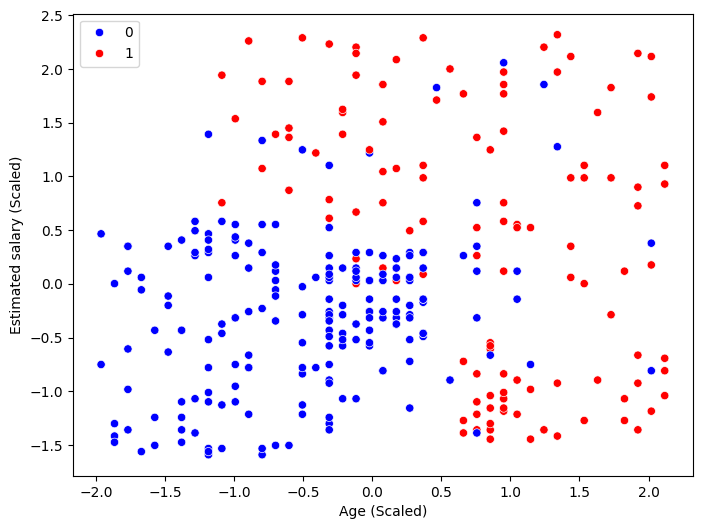

In [15]:
# --- 3. Visualization after Scaling ---
plt.figure(figsize=(8, 6))
sns.scatterplot(x=X_train_scaled[:, 0], y=X_train_scaled[:, 1], hue=y_train, palette={0: 'blue', 1: 'red'}, marker='o')
plt.xlabel("Age (Scaled)")
plt.ylabel("Estimated salary (Scaled)")
plt.show()

In [17]:
# --- 4. Model Training & Evaluation ---
# Using scaled features ensures stable convergence and correct coefficients
classifier = LogisticRegression()
classifier.fit(X_train_scaled, y_train)

LogisticRegression()

In [18]:
y_pred = classifier.predict(X_test_scaled)
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy: {:.2f}%".format(accuracy * 100))

Accuracy: 92.50%


In [19]:
print("Coefficients:", classifier.coef_)
print("Intercept:", classifier.intercept_)

Coefficients: [[2.00319272 1.08067231]]
Intercept: [-0.87067834]


In [20]:
# --- 5. Decision Boundary Visualization (Scaled Data) ---
# Formula for decision boundary (w0 + w1*x1 + w2*x2 = 0) -> x2 = -(w0 + w1*x1) / w2
w0 = classifier.intercept_[0]
w1 = classifier.coef_[0][0]
w2 = classifier.coef_[0][1]

In [21]:
x1 = np.linspace(-3, 3, 100)
x2 = -(w0 + w1 * x1) / w2

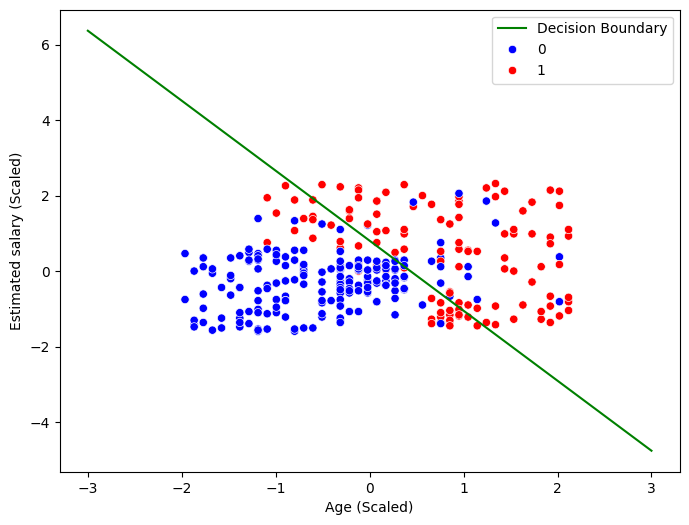

In [22]:
plt.figure(figsize=(8, 6))
plt.plot(x1, x2, color='green', label='Decision Boundary')
sns.scatterplot(x=X_train_scaled[:, 0], y=X_train_scaled[:, 1], hue=y_train, palette={0: 'blue', 1: 'red'}, marker='o')
plt.xlabel("Age (Scaled)")
plt.ylabel("Estimated salary (Scaled)")
plt.legend()
plt.show()

In [23]:
!jupyter nbconvert "/content/drive/MyDrive/Colab Notebooks/Linear_regression_prediction.ipynb" --to html

[NbConvertApp] Converting notebook /content/drive/MyDrive/Colab Notebooks/Linear_regression_prediction.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 3 image(s).
[NbConvertApp] Writing 574029 bytes to /content/drive/MyDrive/Colab Notebooks/Linear_regression_prediction.html
